In [15]:
import json
from pathlib import Path
from collections import Counter, defaultdict
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [16]:
# Project directory
PROJECT_DIR = Path.cwd().resolve().parent

# Dataset directory
DATA_DIR = PROJECT_DIR / "data"

# COCO annotation files
annotation_paths = {
    "train": DATA_DIR / "train" / "_annotations.coco.json",
    "valid": DATA_DIR / "valid" / "_annotations.coco.json",
    "test": DATA_DIR / "test" / "_annotations.coco.json"
}

datasets = {}

for split, path in annotation_paths.items():
    with open(path, "r", encoding="utf-8") as file:
        datasets[split] = json.load(file)

In [17]:
# Summarise dataset size and annotation coverage for each split.
# Images without annotations are identified to understand whether
# the dataset contains background-only images or missing labels.

summary = []

for split, dataset in datasets.items():
    images = dataset["images"]
    annotations = dataset["annotations"]

    annotated_ids = {ann["image_id"] for ann in annotations}

    summary.append({
        "Dataset": split,
        "Images": len(images),
        "Annotations": len(annotations),
        "Images without annotations":
            len(images) - len(annotated_ids)
    })

summary_df = pd.DataFrame(summary)

display(summary_df)

,Dataset,Images,Annotations,Images without annotations
0,train,1764,2232,20
1,valid,115,143,0
2,test,76,91,1


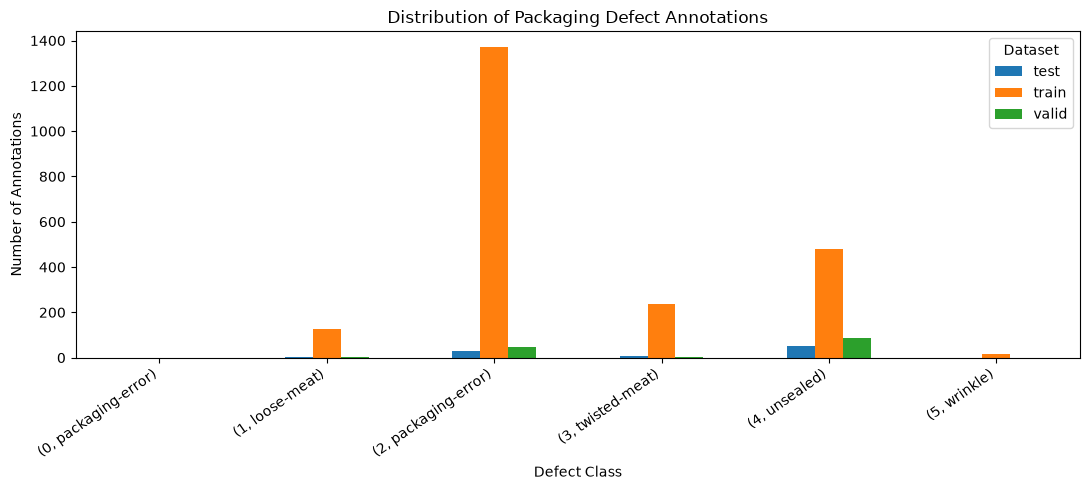

In [18]:
# Get category names
categories = {
    cat["id"]: cat["name"]
    for cat in datasets["train"]["categories"]
}

# Count annotations for each class and dataset split
records = []

for split, dataset in datasets.items():
    counts = Counter(
        ann["category_id"]
        for ann in dataset["annotations"]
    )

    for category_id, name in categories.items():
        records.append({
            "Dataset": split,
            "Class": name,
            "Category ID": category_id,
            "Count": counts.get(category_id, 0)
        })

class_df = pd.DataFrame(records)

# Plot class distribution
pivot_df = class_df.pivot(
    index=["Category ID", "Class"],
    columns="Dataset",
    values="Count"
)

pivot_df.plot(kind="bar", figsize=(11, 5))

plt.title("Distribution of Packaging Defect Annotations")
plt.xlabel("Defect Class")
plt.ylabel("Number of Annotations")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

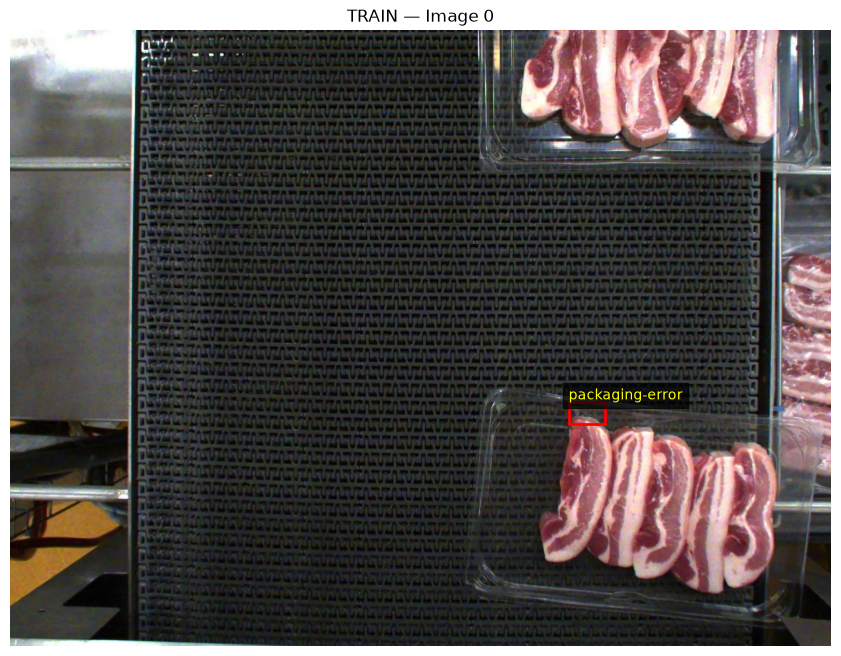

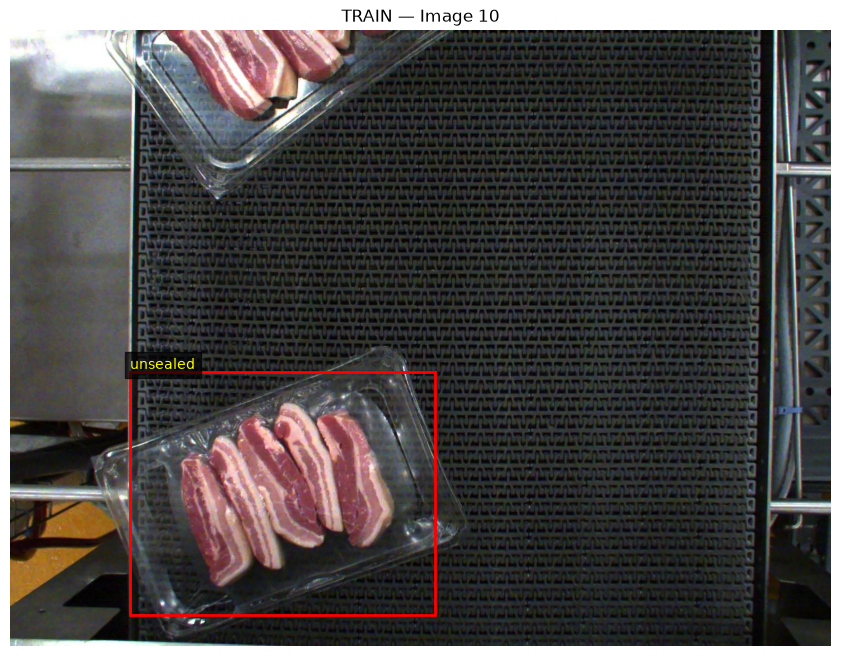

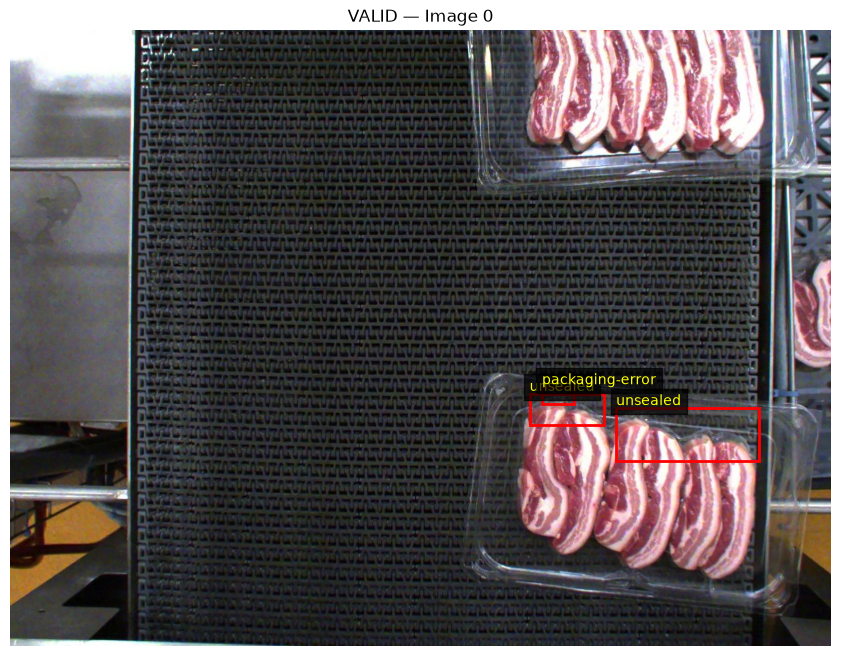

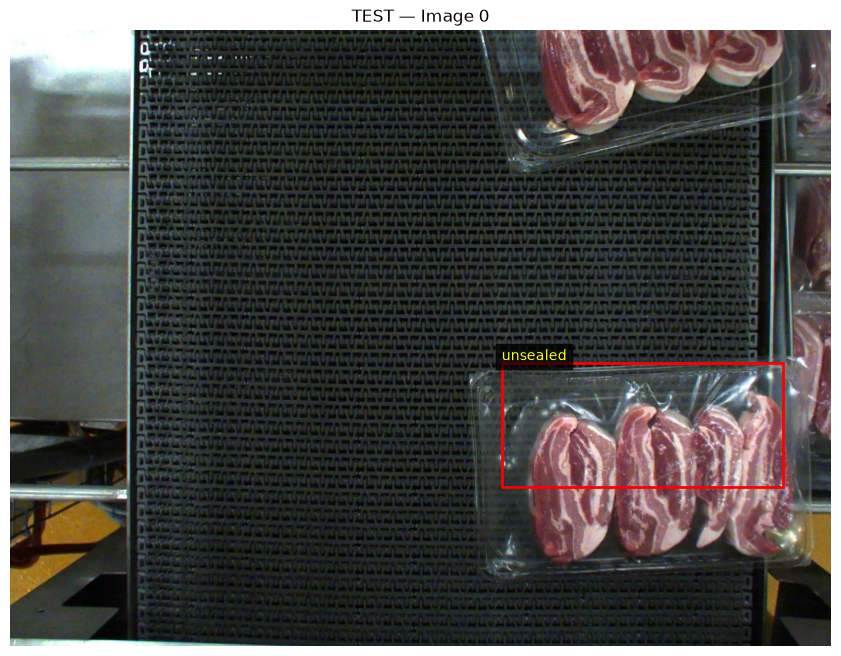

In [19]:

def show_annotations(split="train", image_index=0):
    """Display an image with its COCO ground-truth annotations.

    This function helps visually inspect annotation quality by
    overlaying defect bounding boxes and category labels on the
    original RGB image.

    Args:
        split (str): Dataset split to inspect. Must be one of
            "train", "valid", or "test". Defaults to "train".
        image_index (int): Zero-based index of the image within
            the selected dataset split. Defaults to 0.

    Returns:
        None: Displays the annotated image using Matplotlib.

    Raises:
        KeyError: If the specified dataset split does not exist.
        IndexError: If image_index is outside the available
            image range.
    """
    dataset = datasets[split]

    # Retrieve the image using its COCO metadata so that annotations
    # are matched by image ID rather than filename or list position.
    image_info = dataset["images"][image_index]
    image_path = DATA_DIR / split / image_info["file_name"]

    image = cv2.imread(str(image_path))

    if image is None:
        print(f"Image not found or unreadable: {image_path}")
        return

    # OpenCV loads BGR images, while Matplotlib expects RGB colours.
    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

    # Convert numerical category IDs into readable defect labels.
    category_names = {
        cat["id"]: cat["name"]
        for cat in dataset["categories"]
    }

    # Only display annotations associated with the selected image.
    image_annotations = [
        ann
        for ann in dataset["annotations"]
        if ann["image_id"] == image_info["id"]
    ]

    fig, ax = plt.subplots(figsize=(12, 8))
    ax.imshow(image)

    for ann in image_annotations:
        # COCO bounding boxes follow [x_min, y_min, width, height].
        x, y, w, h = ann["bbox"]
        label = category_names[ann["category_id"]]

        # Overlay each defect region without obscuring the image.
        rect = plt.Rectangle(
            (x, y),
            w,
            h,
            fill=False,
            edgecolor="red",
            linewidth=2,
        )
        ax.add_patch(rect)

        # Position labels slightly above their corresponding boxes.
        ax.text(
            x,
            max(y - 5, 0),
            label,
            color="yellow",
            fontsize=10,
            bbox=dict(facecolor="black", alpha=0.7),
        )

    ax.set_title(f"{split.upper()} — Image {image_index}")
    ax.axis("off")
    plt.show()


# Inspect representative images across all three dataset splits.
# Multiple training examples help reveal variation in annotation quality.
show_annotations("train", 0)
show_annotations("train", 10)
show_annotations("valid", 0)
show_annotations("test", 0)


In [20]:
def original_image_names(dataset):
    """Extract unique original image names from a COCO dataset.

    Roboflow may append export-specific suffixes to image filenames.
    Recovering the original names helps identify images that appear
    in multiple dataset splits under different exported filenames.

    Args:
        dataset (dict): COCO annotation dictionary containing an
            "images" list. Each image record contains a filename
            and may contain original-source metadata under "extra".

    Returns:
        set[str]: Unique original image names found in the dataset.

    Raises:
        KeyError: If the dataset lacks the "images" key or an image
            record lacks a required "file_name".
    """
    names = set()

    for image in dataset["images"]:
        # Prefer original-source metadata when it is available.
        original = image.get("extra", {}).get("name")

        if original is None:
            # Remove the Roboflow export suffix when metadata is absent.
            # This allows exported copies of the same source image
            # to be recognised as potential duplicates.
            original = image["file_name"].split("_jpg.rf.")[0]

        names.add(original)

    return names


# Extract unique source-image names from each dataset split.
train_names = original_image_names(datasets["train"])
valid_names = original_image_names(datasets["valid"])
test_names = original_image_names(datasets["test"])

# Intersections identify source-image names appearing in both splits.
# Any overlap represents potential data leakage that should be
# addressed before training and evaluating the detection models.
print(
    "Train / Validation overlap:",
    len(train_names & valid_names)
)

print(
    "Train / Test overlap:",
    len(train_names & test_names)
)

print(
    "Validation / Test overlap:",
    len(valid_names & test_names)
)


Train / Validation overlap: 12
Train / Test overlap: 11
Validation / Test overlap: 1


In [21]:
# Validate bounding-box geometry across all dataset splits.
# Invalid annotations may cause incorrect model training or
# unreliable evaluation results.
for split, dataset in datasets.items():

    # Map image IDs to metadata for efficient lookup.
    # Each bounding box must be checked against the dimensions
    # of the image to which it belongs.
    images_by_id = {
        img["id"]: img
        for img in dataset["images"]
    }

    invalid_boxes = []

    for ann in dataset["annotations"]:

        # An annotation is invalid if its referenced image
        # does not exist in the COCO image records.
        img = images_by_id.get(ann["image_id"])

        if img is None:
            invalid_boxes.append(ann["id"])
            continue

        # COCO bounding boxes use [x_min, y_min, width, height].
        x, y, w, h = ann["bbox"]

        # Bounding boxes must have positive dimensions, start
        # within the image, and remain inside image boundaries.
        # The small tolerance avoids flagging floating-point
        # rounding differences as annotation errors.
        if (
            w <= 0
            or h <= 0
            or x < 0
            or y < 0
            or x + w > img["width"] + 1e-6
            or y + h > img["height"] + 1e-6
        ):
            invalid_boxes.append(ann["id"])

    # Report the number of invalid annotations in each split.
    print(
        f"{split}: {len(invalid_boxes)} invalid bounding boxes"
    )


train: 0 invalid bounding boxes
valid: 0 invalid bounding boxes
test: 0 invalid bounding boxes


In [22]:
# Identify original image names shared between dataset splits.
# These overlaps indicate potential data leakage and must be
# addressed before model training and independent evaluation.
overlap_train_valid = train_names & valid_names
overlap_train_test = train_names & test_names
overlap_valid_test = valid_names & test_names

# Display the overlapping filenames to support investigation
# and subsequent dataset cleaning in Notebook 02.
print("TRAIN / VALIDATION OVERLAPS:")
for name in sorted(overlap_train_valid):
    print(name)

print("\nTRAIN / TEST OVERLAPS:")
for name in sorted(overlap_train_test):
    print(name)

print("\nVALIDATION / TEST OVERLAPS:")
for name in sorted(overlap_valid_test):
    print(name)


TRAIN / VALIDATION OVERLAPS:
frame_with_red_1946.jpg
frame_with_red_2223.jpg
frame_with_red_2247.jpg
frame_with_red_2409.jpg
frame_with_red_4704.jpg
frame_with_red_6510.jpg
frame_with_red_7277.jpg
frame_with_red_7508.jpg
frame_with_red_7555.jpg
frame_with_red_7653.jpg
frame_with_red_7665.jpg
frame_with_red_7783.jpg

TRAIN / TEST OVERLAPS:
frame_with_red_1458.jpg
frame_with_red_1521.jpg
frame_with_red_3640.jpg
frame_with_red_4145.jpg
frame_with_red_4170.jpg
frame_with_red_5732.jpg
frame_with_red_5849.jpg
frame_with_red_692.jpg
frame_with_red_7506.jpg
frame_with_red_8146.jpg
frame_with_red_8565.jpg

VALIDATION / TEST OVERLAPS:
frame_with_red_3482.jpg


In [23]:
# Combine the overlapping original image names from all split pairs.
# A set union ensures each original name appears only once,
# even if it occurs in all three dataset splits.
overlapping_names = (
    overlap_train_valid
    | overlap_train_test
    | overlap_valid_test
)

records = []

for split, dataset in datasets.items():
    for image in dataset["images"]:

        # Use the same original-name extraction logic as Cell 5
        # to ensure exported copies are matched consistently.
        original_name = image.get("extra", {}).get("name")

        if original_name is None:
            original_name = image["file_name"].split("_jpg.rf.")[0]

        # Record every exported image associated with a shared
        # original name, including its split and unique image ID.
        if original_name in overlapping_names:
            records.append({
                "Original image": original_name,
                "Dataset": split,
                "File name": image["file_name"],
                "Image ID": image["id"],
            })

# Organise matching records into a table to help trace
# duplicate images during dataset preparation in Notebook 02.
overlap_df = pd.DataFrame(
    records,
    columns=["Original image", "Dataset", "File name", "Image ID"],
)

display(
    overlap_df.sort_values(
        ["Original image", "Dataset"]
    ).reset_index(drop=True)
)

,Original image,Dataset,File name,Image ID
0,frame_with_red_1458.jpg,test,frame_with_red_1458_jpg.rf.e1909c7fa9adac6d0d7...,67
1,frame_with_red_1458.jpg,train,frame_with_red_1458_jpg.rf.3a50cd630278f50d3cc...,1369
2,frame_with_red_1521.jpg,test,frame_with_red_1521_jpg.rf.ec336bad538d3ddd4e5...,69
3,frame_with_red_1521.jpg,train,frame_with_red_1521_jpg.rf.045e4c93704a6be3130...,897
4,frame_with_red_1946.jpg,train,frame_with_red_1946_jpg.rf.2620724c7968d80d06d...,643
5,frame_with_red_1946.jpg,valid,frame_with_red_1946_jpg.rf.701286f669609d99bb1...,58
6,frame_with_red_2223.jpg,train,frame_with_red_2223_jpg.rf.0dc3e719553ea032b11...,792
7,frame_with_red_2223.jpg,valid,frame_with_red_2223_jpg.rf.e49d6f3a1c2b90ca68c...,74
8,frame_with_red_2247.jpg,train,frame_with_red_2247_jpg.rf.e957af9b30cdb625a07...,1376
9,frame_with_red_2247.jpg,valid,frame_with_red_2247_jpg.rf.09be7099400db47ec4d...,76
